# 02 · Comparing the disproportionality methods

`make scores` scored every drug-event pair with four methods (see the README).
Before evaluating them against a ground truth (Phase 4), this notebook looks at
how they behave on the same data:

1. How many signals does each method raise, and how much do they agree?
2. How does each method treat pairs with very few reports?
3. Do they all find well-known adverse reactions?

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

from faers import plotting as P

DB = Path("../data/faers_warehouse.duckdb")
FIGURES = Path("../reports/figures")
con = duckdb.connect(str(DB), read_only=True)


def sql(query):
    return con.execute(query).df()


METHODS = ["prr", "ror", "bcpnn", "ebgm"]
LABELS = {"prr": "PRR", "ror": "ROR", "bcpnn": "BCPNN", "ebgm": "EBGM"}

P.apply_style()


def save(fig, name):
    P.save(fig, name, folder=FIGURES)


prior = sql("SELECT * FROM ebgm_prior")
prior

,alpha1,beta1,alpha2,beta2,p
0,0.000125,0.00938,0.466912,0.672056,0.987535


## 1. Number of signals and agreement

In [2]:
signals = sql("""
    SELECT COUNT(*) AS pairs,
           SUM(prr_signal::INT) AS prr, SUM(ror_signal::INT) AS ror,
           SUM(bcpnn_signal::INT) AS bcpnn, SUM(ebgm_signal::INT) AS ebgm
    FROM signal_scores
""")
counts = signals[METHODS].T.rename(columns={0: "signals"})
counts["% of pairs"] = 100 * counts.signals / signals.pairs[0]
counts.index = [LABELS[m] for m in counts.index]
counts.style.format({"signals": "{:,.0f}", "% of pairs": "{:.1f}"})

,signals,% of pairs
PRR,"361,088",15.8
ROR,"416,773",18.2
BCPNN,"342,723",15.0
EBGM,"226,987",9.9


In [3]:
flags = sql("SELECT prr_signal, ror_signal, bcpnn_signal, ebgm_signal FROM signal_scores")
flags.columns = METHODS

# Jaccard index: pairs flagged by both methods / pairs flagged by at least one.
jaccard = pd.DataFrame(index=METHODS, columns=METHODS, dtype=float)
for m1 in METHODS:
    for m2 in METHODS:
        both = (flags[m1] & flags[m2]).sum()
        either = (flags[m1] | flags[m2]).sum()
        jaccard.loc[m1, m2] = both / either
jaccard.index = jaccard.columns = [LABELS[m] for m in METHODS]
print("Agreement between methods (Jaccard index, 1 = identical signal lists)")
jaccard.round(2)

Agreement between methods (Jaccard index, 1 = identical signal lists)


,PRR,ROR,BCPNN,EBGM
PRR,1.00,0.87,0.81,0.56
ROR,0.87,1.00,0.82,0.49
BCPNN,0.81,0.82,1.00,0.59
EBGM,0.56,0.49,0.59,1.00


In [4]:
n_methods = flags.sum(axis=1)
flagged = n_methods[n_methods > 0]
agreement = flagged.value_counts().sort_index()
print(f"Pairs flagged by at least one method: {len(flagged):,}")
for k, n in agreement.items():
    print(f"  flagged by {k} method(s): {n:,} ({100 * n / len(flagged):.1f}%)")

# Which methods are alone when only one method flags a pair?
alone = flags[n_methods == 1].sum()
print("\nPairs flagged by a single method:")
print(alone.rename(LABELS).to_string())

Pairs flagged by at least one method: 431,806
  flagged by 1 method(s): 43,593 (10.1%)
  flagged by 2 method(s): 72,615 (16.8%)
  flagged by 3 method(s): 103,644 (24.0%)
  flagged by 4 method(s): 211,954 (49.1%)

Pairs flagged by a single method:
PRR          0
ROR      28560
BCPNN        0
EBGM     15033


## 2. Behaviour with few reports

The share of pairs flagged, by the number of co-reports `a`. PRR and ROR need
at least 3 reports by construction; BCPNN and EBGM have no hard minimum but
shrink small counts towards "no association".

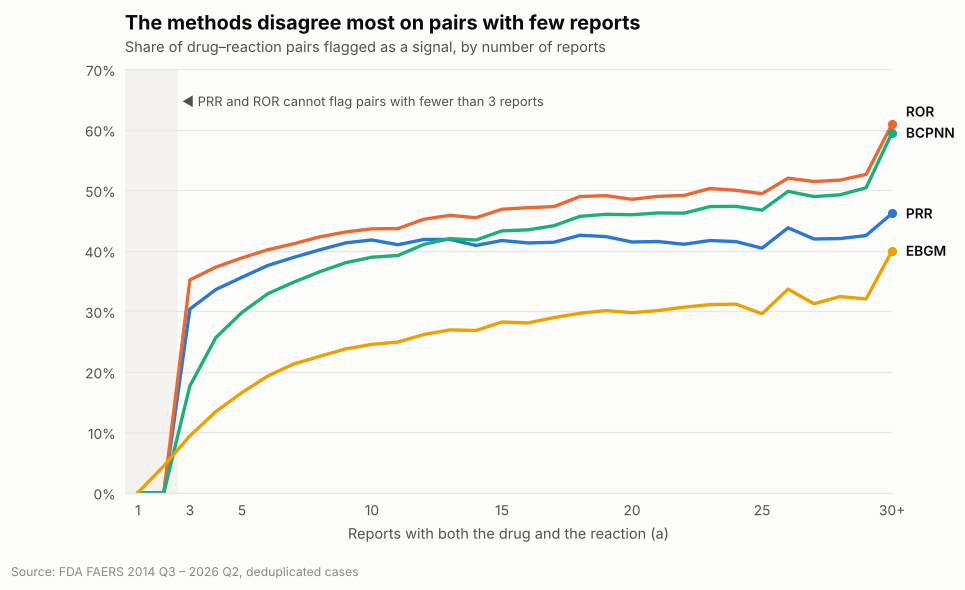

In [5]:
by_a = sql("""
    SELECT LEAST(a, 30) AS a,
           100 * AVG(prr_signal::INT) AS prr, 100 * AVG(ror_signal::INT) AS ror,
           100 * AVG(bcpnn_signal::INT) AS bcpnn, 100 * AVG(ebgm_signal::INT) AS ebgm
    FROM signal_scores GROUP BY 1 ORDER BY 1
""")

fig, ax = plt.subplots(figsize=(9, 5))
ax.axvspan(0.5, 2.5, color="#f3f2ee", zorder=0)
ax.text(2.7, 66, "◀ PRR and ROR cannot flag pairs with fewer than 3 reports", fontsize=8.5,
        color=P.MUTED, ha="left", va="top")
series = {}
for m in METHODS:
    ax.plot(by_a.a, by_a[m], color=P.METHOD_COLORS[LABELS[m]])
    series[LABELS[m]] = by_a[m].to_numpy()
ax.set_xlim(0.5, 30)
ax.set_ylim(0, 70)
P.end_labels(ax, 30, series, P.METHOD_COLORS, min_gap=3.5)
ax.set_xticks([1, 3, 5, 10, 15, 20, 25, 30], ["1", "3", "5", "10", "15", "20", "25", "30+"])
P.percent(ax)
ax.set_xlabel("Reports with both the drug and the reaction (a)")
P.headline(ax, "The methods disagree most on pairs with few reports",
           "Share of drug–reaction pairs flagged as a signal, by number of reports")
P.source_note(fig)
save(fig, "signals_by_count")

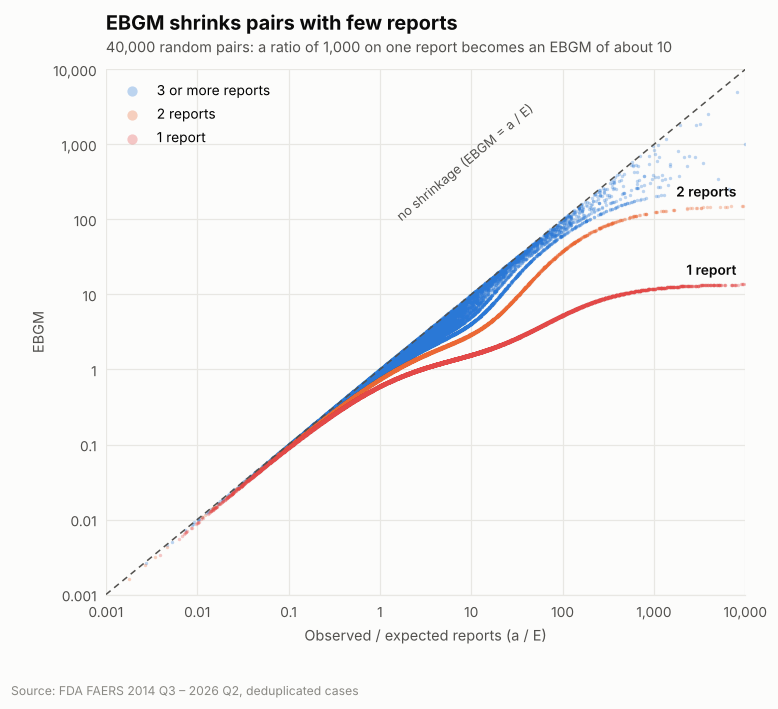

In [6]:
# Shrinkage: EBGM against the raw observed/expected ratio, on a random sample of pairs.
sample = sql("""
    SELECT a, a / expected AS raw_ratio, ebgm FROM signal_scores USING SAMPLE 40000 (reservoir, 42)
""")
fig, ax = plt.subplots(figsize=(7.5, 6.2))
groups = [(sample.a >= 3, P.ACCENT, "3 or more reports"), (sample.a == 2, P.HIGHLIGHT, "2 reports"),
          (sample.a == 1, "#e34948", "1 report")]
for mask, color, label in groups:
    ax.scatter(sample.raw_ratio[mask], sample.ebgm[mask], s=5, alpha=0.3, color=color,
               linewidths=0, label=label)
lims = [1e-3, 1e4]
ax.plot(lims, lims, color=P.MUTED, linewidth=1, linestyle=(0, (4, 3)))
ax.annotate("no shrinkage (EBGM = a / E)", (60, 60), xytext=(-4, 10), textcoords="offset points",
            color=P.MUTED, fontsize=8.5, rotation=40, ha="right")
for a_value, label in [(1, "1 report"), (2, "2 reports")]:
    top = sample[sample.a == a_value].ebgm.max()
    ax.annotate(label, (8e3, top), xytext=(0, 6), textcoords="offset points", ha="right",
                fontsize=9, fontweight="semibold", color=P.INK)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(*lims)
ax.set_ylim(*lims)
P.plain_log(ax, "x")
P.plain_log(ax, "y")
ax.grid(axis="x", visible=True)
ax.set_xlabel("Observed / expected reports (a / E)")
ax.set_ylabel("EBGM")
ax.legend(loc="upper left", markerscale=3)
P.headline(ax, "EBGM shrinks pairs with few reports",
           "40,000 random pairs: a ratio of 1,000 on one report becomes an EBGM of about 10")
P.source_note(fig)
save(fig, "ebgm_shrinkage")

## 3. Well-known adverse reactions

Four reactions that are on the drug labels (positive controls) and one
pair that should not be a signal (negative control).

In [7]:
known = sql("""
    SELECT drug, pt, a, ROUND(expected, 1) AS expected,
           ROUND(prr, 1) AS prr, ROUND(ror_lower, 1) AS ror_lower,
           ROUND(ic025, 2) AS ic025, ROUND(eb05, 1) AS eb05,
           prr_signal AND ror_signal AND bcpnn_signal AND ebgm_signal AS all_methods
    FROM signal_scores
    WHERE (drug, pt) IN (
        ('LEVOFLOXACIN', 'tendon rupture'), ('AMIODARONE', 'pulmonary fibrosis'),
        ('SEMAGLUTIDE', 'optic ischaemic neuropathy'), ('MONTELUKAST', 'suicidal ideation'),
        ('ADALIMUMAB', 'nausea'))
    ORDER BY eb05 DESC
""")
known

,drug,pt,a,expected,prr,ror_lower,ic025,eb05,all_methods
0,LEVOFLOXACIN,tendon rupture,1196,14.3,98.1,96.6,6.24,79.4,True
1,SEMAGLUTIDE,optic ischaemic neuropathy,835,12.5,102.4,95.1,5.89,63.1,True
2,AMIODARONE,pulmonary fibrosis,770,13.5,60.6,59.4,5.67,53.8,True
3,MONTELUKAST,suicidal ideation,1354,59.3,23.3,24.3,4.41,21.8,True
4,ADALIMUMAB,nausea,12455,17615.6,0.7,0.7,-0.53,0.7,False


## 4. Key findings

- **Very different signal volumes:** ROR flags the most pairs (417 k, 18 %), then PRR (361 k) and BCPNN (343 k). EBGM is clearly the most conservative (227 k, 10 %).
- **PRR, ROR and BCPNN largely agree** (Jaccard 0.81–0.87): with many reports they are almost the same ratio. **EBGM is the odd one out** (Jaccard 0.49–0.59).
- Half of the pairs flagged by any method (49 %) are flagged by all four. When only one method flags a pair, it is always ROR (28.6 k pairs, mostly small counts with wide intervals) or EBGM (15.0 k).
- **Small counts are where the methods really differ.** PRR and ROR cannot flag anything below 3 reports by design. BCPNN needs about 3 reports to get its lower bound above zero. EBGM can flag a pair with 2 reports when the ratio is very large, but for most of the range it requires much more evidence than the others.
- **Shrinkage works as intended:** pairs with 1 or 2 reports are pulled far below their raw observed/expected ratio, while pairs with many reports keep it.
- The fitted MGPS prior has one almost degenerate component (alpha1 ≈ 0.0001). It is a known behaviour of the zero-truncated fit on very sparse data, and it should be checked against the reference implementation (openEBGM, R) before trusting EBGM's small-count behaviour.
- The four well-known adverse reactions are flagged by all methods, and the negative control is flagged by none. **The full-window results cannot separate the methods; the real question is which one ranks true reactions higher and which one flags them earlier.** That is Phase 4: evaluation against a dated reference set, using `counts_as_of()` quarter by quarter.
